In [1]:
# install every tools needed first

import os

In [2]:

!pip install pandas


In [3]:
!pip install scikit-learn xgboost imbalanced-learn


In [4]:
%pip install matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [5]:
# loading and inspecting the dataset

import pandas as pd

df = pd.read_csv('paysim.csv')

print(df.shape)
print(df.isnull().sum())
df.head()


(6362620, 11)
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [6]:
# Cleaning and Data Processing

# transforming non numerical columns and categorical features of the data to numeric indicators.

df = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'])
df = pd.get_dummies(df, columns=['type'], drop_first=True)
df.head()


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,False,False,True,False
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,False,False,True,False
2,1,181.00,181.0,0.00,0.0,0.0,1,False,False,False,True
3,1,181.00,181.0,0.00,21182.0,0.0,1,True,False,False,False
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,False,False,True,False


In [7]:

# splitting dataset into Features and Target Variables

X = df.drop(columns=['isFraud'])
y = df['isFraud']

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)


Features shape (X): (6362620, 10)
Target shape (y): (6362620,)


In [8]:
#Seperating Data into Training and Testing Sets 

# splitting dataset into training and testing sets using an 80/20 ratio. 80% of the data to look at patterns and learn how to detect fraud. The remaining 20% to evaluate real world performance

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)


Training features: (5090096, 10)
Testing features: (1272524, 10)


In [9]:
#Fixing Class Imbalance

# Downsampling the majority class to fix class imbalance in the training dataset.

import pandas as pd

train_data = pd.concat([X_train, y_train], axis=1)

fraud = train_data[train_data['isFraud'] == 1]
legit = train_data[train_data['isFraud'] == 0]

legit_downsampled = legit.sample(n=len(fraud), random_state=42)

balanced_train = pd.concat([fraud, legit_downsampled])
balanced_train = balanced_train.sample(frac=1, random_state=42)

X_train_balanced = balanced_train.drop(columns=['isFraud'])
y_train_balanced = balanced_train['isFraud']

print("Balanced Training features:", X_train_balanced.shape)
print("Balanced Target distribution:\n", y_train_balanced.value_counts())


Balanced Training features: (13140, 10)
Balanced Target distribution:
 isFraud
1    6570
0    6570
Name: count, dtype: int64


In [10]:
#Training the ML Model

# Evaluating the model using the testing set to calculate classification metrics using Random Forest classifier model

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_balanced, y_train_balanced)

print("Model training complete!")



Model training complete!


In [11]:
#Evaluating Baseline Precision and Recall

from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      0.99      0.99   1270881
           1       0.09      1.00      0.17      1643

    accuracy                           0.99   1272524
   macro avg       0.55      0.99      0.58   1272524
weighted avg       1.00      0.99      0.99   1272524



In [12]:
# Adjusting the classification threshold to reduce false positives and improve precision.

import numpy as np
from sklearn.metrics import classification_report

y_scores = model.predict_proba(X_test)[:, 1]
y_pred_strict = (y_scores >= 0.90).astype(int)
print(classification_report(y_test, y_pred_strict))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.42      0.93      0.58      1643

    accuracy                           1.00   1272524
   macro avg       0.71      0.97      0.79   1272524
weighted avg       1.00      1.00      1.00   1272524



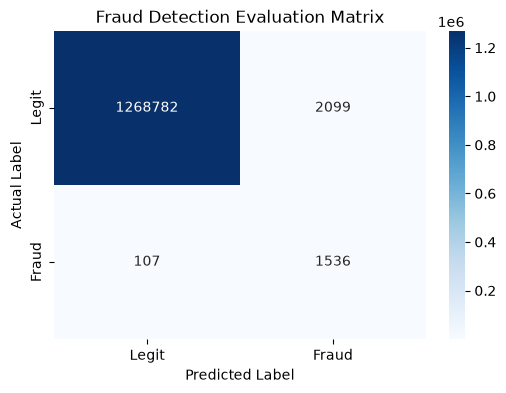

In [13]:
# Visualizing the Evaluation Matrix
# Visualizing the final evaluation results using a confusion matrix chart

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_strict)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Fraud Detection Evaluation Matrix')
plt.show()



In [14]:
import joblib
joblib.dump(model, 'fraud_model.pkl')


['fraud_model.pkl']